# Exploratory Data Analysis  
## Cervical Cancer (Risk Factors) Dataset

# Introduction
The purpose of this notebook is to perform an Exploratory Data Analysis (EDA) on the Cervical Cancer (Risk Factors) dataset.

**The main objectives are:**
* **To understand the structure** of the dataset.
* **To assess data quality** and identify potential issues.
* **To analyze missing values** and inconsistencies.
* **To explore the distributions** of key variables.
* **To identify potential relationships** with the target variable (**Biopsy**).

This analysis provides the foundation for subsequent modeling and performance benchmarking.

In [41]:
import pandas as pd
import numpy as np
df = pd.read_csv("risk_factors_cervical_cancer.csv") #Load the dataset from CSV file into a pandas DataFrame
df.head() #Display first rows to verify correct loading and inspect structure

df.shape #Get dataset dimensions (number of rows and columns)
n_rows = df.shape[0]
n_cols = df.shape[1]
print("Počet pacientok:", n_rows)
print("Počet atribútov:", n_cols, "\n")

df.info #Display dataset structure, data types, and non-null values
df.describe().T #Compute descriptive statistics for numerical variables

Počet pacientok: 858
Počet atribútov: 36 



,count,mean,std,min,25%,50%,75%,max
Age,858.0,26.820513,8.497948,13.0,20.0,25.0,32.0,84.0
STDs: Number of diagnosis,858.0,0.087413,0.302545,0.0,0.0,0.0,0.0,3.0
Dx:Cancer,858.0,0.020979,0.143398,0.0,0.0,0.0,0.0,1.0
Dx:CIN,858.0,0.010490,0.101939,0.0,0.0,0.0,0.0,1.0
Dx:HPV,858.0,0.020979,0.143398,0.0,0.0,0.0,0.0,1.0
Dx,858.0,0.027972,0.164989,0.0,0.0,0.0,0.0,1.0
Hinselmann,858.0,0.040793,0.197925,0.0,0.0,0.0,0.0,1.0
Schiller,858.0,0.086247,0.280892,0.0,0.0,0.0,0.0,1.0
Citology,858.0,0.051282,0.220701,0.0,0.0,0.0,0.0,1.0
Biopsy,858.0,0.064103,0.245078,0.0,0.0,0.0,0.0,1.0


In [42]:
print(df.dtypes.value_counts(), "\n") #Count the number of columns by data type before cleaning
df = df.replace('?', pd.NA) #Replace '?' with standard missing value (NaN) and convert all columns to numeric
df = df.apply(pd.to_numeric)
print(df.dtypes.value_counts()) #Count the number of columns by data type after conversion
df.select_dtypes(include='object').columns # Check if any columns still have object type

object    26
int64     10
Name: count, dtype: int64 

float64    26
int64      10
Name: count, dtype: int64


Index([], dtype='object')

In [43]:
numeric_cols = [] #Initialize lists to store numeric and binary columns
binary_cols = []

for col in df.columns: #Iterate over each column to classify as binary (0/1) or numeric
    unique_vals = df[col].dropna().unique()
    if set(unique_vals).issubset({0, 1}):
        binary_cols.append(col)
    else:
        numeric_cols.append(col)

print("Počet binárnych premenných:", len(binary_cols)) #Print counts of binary and numeric columns
print("Počet numerických premenných:", len(numeric_cols))

Počet binárnych premenných: 24
Počet numerických premenných: 12


In [44]:
for col in binary_cols: #For each binary column, print the column name and its unique non-missing values
    print(col, df[col].dropna().unique())

Smokes [0. 1.]
Hormonal Contraceptives [0. 1.]
IUD [0. 1.]
STDs [0. 1.]
STDs:condylomatosis [0. 1.]
STDs:cervical condylomatosis [0.]
STDs:vaginal condylomatosis [0. 1.]
STDs:vulvo-perineal condylomatosis [0. 1.]
STDs:syphilis [0. 1.]
STDs:pelvic inflammatory disease [0. 1.]
STDs:genital herpes [0. 1.]
STDs:molluscum contagiosum [0. 1.]
STDs:AIDS [0.]
STDs:HIV [0. 1.]
STDs:Hepatitis B [0. 1.]
STDs:HPV [0. 1.]
Dx:Cancer [0 1]
Dx:CIN [0 1]
Dx:HPV [0 1]
Dx [0 1]
Hinselmann [0 1]
Schiller [0 1]
Citology [0 1]
Biopsy [0 1]


In [45]:
df[binary_cols].nunique().sort_values() #Count the number of unique values in each binary column and sort the results

STDs:cervical condylomatosis          1
STDs:AIDS                             1
Smokes                                2
Schiller                              2
Hinselmann                            2
Dx                                    2
Dx:HPV                                2
Dx:CIN                                2
Dx:Cancer                             2
STDs:HPV                              2
STDs:Hepatitis B                      2
STDs:HIV                              2
STDs:molluscum contagiosum            2
STDs:genital herpes                   2
STDs:pelvic inflammatory disease      2
STDs:syphilis                         2
STDs:vulvo-perineal condylomatosis    2
STDs:vaginal condylomatosis           2
STDs:condylomatosis                   2
STDs                                  2
IUD                                   2
Hormonal Contraceptives               2
Citology                              2
Biopsy                                2
dtype: int64

In [46]:
invalid_binary = {} #Initialize a dictionary to store binary columns with unexpected values

for col in binary_cols:                         #Verify integrity of binary data: check for unexpected values in columns classified as binary
    unique_vals = set(df[col].dropna().unique())
    if not unique_vals.issubset({0, 1}):        
        invalid_binary[col] = unique_vals

invalid_binary #Display binary columns with invalid values (should be empty if all binary columns are clean)

{}

In [47]:
summary_structure = { #Create a summary dictionary of dataset structure
    "Počet pacientok": n_rows,
    "Počet atribútov": n_cols,
    "Počet binárnych premenných": len(binary_cols),
    "Počet numerických premenných": len(numeric_cols),
    "Počet object premenných": len(df.select_dtypes(include='object').columns)
}
summary_structure

{'Počet pacientok': 858,
 'Počet atribútov': 36,
 'Počet binárnych premenných': 24,
 'Počet numerických premenných': 12,
 'Počet object premenných': 0}

In [48]:
missing_count = df.isna().sum() #Count the number of missing values in each column
missing_count

missing_percent = (df.isna().sum() / len(df)) * 100 #Calculate the percentage of missing values per column
missing_percent 

Age                                    0.000000
Number of sexual partners              3.030303
First sexual intercourse               0.815851
Num of pregnancies                     6.526807
Smokes                                 1.515152
Smokes (years)                         1.515152
Smokes (packs/year)                    1.515152
Hormonal Contraceptives               12.587413
Hormonal Contraceptives (years)       12.587413
IUD                                   13.636364
IUD (years)                           13.636364
STDs                                  12.237762
STDs (number)                         12.237762
STDs:condylomatosis                   12.237762
STDs:cervical condylomatosis          12.237762
STDs:vaginal condylomatosis           12.237762
STDs:vulvo-perineal condylomatosis    12.237762
STDs:syphilis                         12.237762
STDs:pelvic inflammatory disease      12.237762
STDs:genital herpes                   12.237762
STDs:molluscum contagiosum            12

In [49]:
missing_table = pd.DataFrame({ #Create a table summarizing missing values for each feature
    'Missing count': df.isna().sum(),
    'Missing %': df.isna().mean() * 100
}).reset_index()

missing_table = missing_table.rename(columns={'index': 'Feature'})
missing_table = missing_table.sort_values(by='Missing %', ascending=False)
missing_table
#missing_table[missing_table['Missing %'] > 50] #Optionally, filter features with more than 50% missing values

,Feature,Missing count,Missing %
27,STDs: Time since last diagnosis,787,91.724942
26,STDs: Time since first diagnosis,787,91.724942
9,IUD,117,13.636364
10,IUD (years),117,13.636364
7,Hormonal Contraceptives,108,12.587413
8,Hormonal Contraceptives (years),108,12.587413
18,STDs:pelvic inflammatory disease,105,12.237762
16,STDs:vulvo-perineal condylomatosis,105,12.237762
24,STDs:HPV,105,12.237762
23,STDs:Hepatitis B,105,12.237762


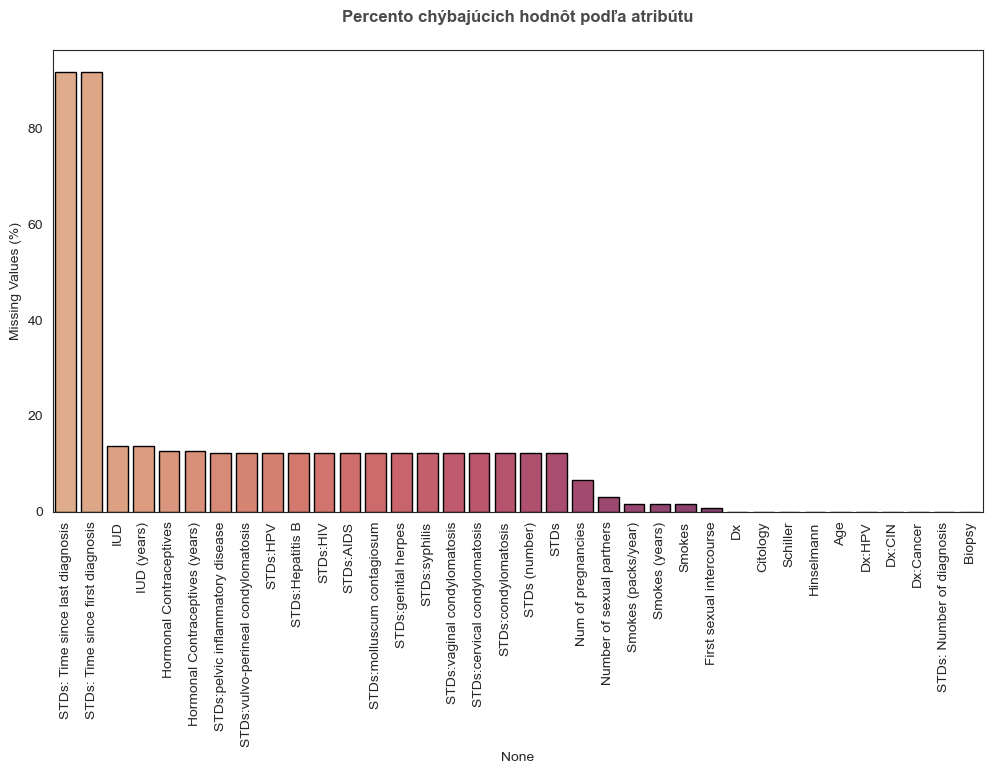

In [50]:
import matplotlib.pyplot as plt
import seaborn as sns

missing_percent = df.isna().mean() * 100
missing_percent = missing_percent.sort_values(ascending=False)

#Create the bar plot of missing values
plt.figure(figsize=(12,6)) 
sns.barplot(
    x=missing_percent.index, 
    y=missing_percent.values, 
    edgecolor='black',
    palette="flare", 
    hue=missing_percent.index, 
    legend=False
)

plt.xticks(rotation=90)
plt.ylabel("Missing Values (%)")
plt.title("Percento chýbajúcich hodnôt podľa atribútu", fontweight='bold', pad=20, color='#4A4A4A')
plt.savefig('missing_values_plot.png', dpi=300, bbox_inches='tight')
plt.show()

In [51]:
row_missing = df.isna().sum(axis=1) #Count missing values per row and show descriptive statistics
row_missing.describe()

count    858.000000
mean       4.221445
std        5.974071
min        0.000000
25%        2.000000
50%        2.000000
75%        2.000000
max       23.000000
dtype: float64

In [52]:
df[row_missing > 15] #Filter and display rows with more than 15 missing values
#df[['STDs', 'STDs: Time since first diagnosis']].head(30) #Optionally, preview the first 30 rows of specific columns

,Age,Number of sexual partners,First sexual intercourse,Num of pregnancies,Smokes,Smokes (years),Smokes (packs/year),Hormonal Contraceptives,Hormonal Contraceptives (years),IUD,...,STDs: Time since first diagnosis,STDs: Time since last diagnosis,Dx:Cancer,Dx:CIN,Dx:HPV,Dx,Hinselmann,Schiller,Citology,Biopsy
71,34,NaN,NaN,3.0,0.0,0.0,0.00,NaN,NaN,NaN,...,NaN,NaN,0,0,0,0,0,0,0,0
74,35,2.0,17.0,2.0,1.0,15.0,0.32,NaN,NaN,NaN,...,NaN,NaN,0,0,0,0,0,0,0,0
90,36,1.0,13.0,6.0,0.0,0.0,0.00,NaN,NaN,NaN,...,NaN,NaN,0,0,0,0,0,0,0,0
95,31,4.0,16.0,2.0,0.0,0.0,0.00,NaN,NaN,NaN,...,NaN,NaN,0,0,0,0,0,0,0,0
98,31,1.0,20.0,5.0,0.0,0.0,0.00,NaN,NaN,NaN,...,NaN,NaN,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
792,23,3.0,15.0,1.0,1.0,5.0,0.75,NaN,NaN,NaN,...,NaN,NaN,0,0,0,0,0,0,0,0
794,20,2.0,16.0,1.0,0.0,0.0,0.00,NaN,NaN,NaN,...,NaN,NaN,0,0,0,0,0,0,0,0
807,36,2.0,18.0,NaN,1.0,19.0,7.60,1.0,8.00,NaN,...,NaN,NaN,0,0,0,0,0,0,0,0
814,16,1.0,12.0,NaN,0.0,0.0,0.00,1.0,0.42,NaN,...,NaN,NaN,0,0,0,0,0,0,0,1


In [53]:
target_counts = df['Biopsy'].value_counts().sort_index() #Count the number of occurrences for each class in the target variable 'Biopsy' and sort by class label
target_counts

Biopsy
0    803
1     55
Name: count, dtype: int64

In [54]:
target_percent = df['Biopsy'].value_counts(normalize=True).sort_index() * 100 #Calculate the percentage distribution of each class in the target variable 'Biopsy' and sort by class label
target_percent 

Biopsy
0    93.589744
1     6.410256
Name: proportion, dtype: float64

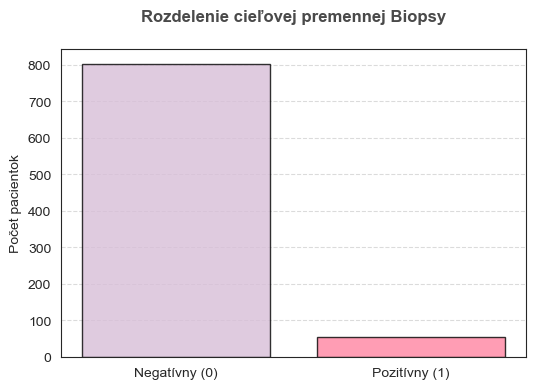

In [55]:
# Plot a bar chart showing the count of negative (0) and positive (1) biopsy outcomes
plt.figure(figsize=(6, 4))
counts = df['Biopsy'].value_counts().sort_index()
colors = ['#D8BFD8', '#FF85A1'] 
plt.bar(['Negatívny (0)', 'Pozitívny (1)'], counts, edgecolor='black', color=colors, alpha=0.8)
plt.ylabel("Počet pacientok")
plt.title("Rozdelenie cieľovej premennej Biopsy", fontweight='bold', pad=20, color='#4A4A4A')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.savefig('missing_values_plot.png', dpi=300, bbox_inches='tight')
plt.show()

In [56]:
df.sort_values(by='Biopsy', ascending=False).head(10) #Display the first 10 rows with the highest values of the target variable 'Biopsy'

,Age,Number of sexual partners,First sexual intercourse,Num of pregnancies,Smokes,Smokes (years),Smokes (packs/year),Hormonal Contraceptives,Hormonal Contraceptives (years),IUD,...,STDs: Time since first diagnosis,STDs: Time since last diagnosis,Dx:Cancer,Dx:CIN,Dx:HPV,Dx,Hinselmann,Schiller,Citology,Biopsy
653,21,1.0,17.0,NaN,0.0,0.0,0.0,1.0,3.00,0.0,...,NaN,NaN,0,1,0,1,0,0,0,1
598,17,2.0,15.0,1.0,0.0,0.0,0.0,0.0,0.00,0.0,...,NaN,NaN,0,0,0,0,1,1,0,1
377,20,2.0,14.0,4.0,1.0,3.0,3.0,1.0,0.50,0.0,...,NaN,NaN,0,0,0,0,0,0,0,1
688,28,5.0,15.0,4.0,0.0,0.0,0.0,0.0,0.00,0.0,...,NaN,NaN,0,0,0,0,0,1,1,1
687,33,3.0,16.0,4.0,1.0,14.0,1.4,1.0,1.00,0.0,...,16.0,16.0,0,0,0,0,0,1,1,1
383,19,2.0,15.0,3.0,0.0,0.0,0.0,1.0,0.58,0.0,...,NaN,NaN,0,0,0,0,1,1,0,1
797,33,3.0,19.0,3.0,0.0,0.0,0.0,1.0,0.16,1.0,...,NaN,NaN,1,0,1,1,1,1,0,1
64,38,2.0,15.0,4.0,0.0,0.0,0.0,1.0,16.00,0.0,...,NaN,NaN,1,0,1,0,0,1,0,1
185,28,2.0,17.0,NaN,0.0,0.0,0.0,1.0,9.00,0.0,...,NaN,NaN,0,0,0,0,1,1,0,1
496,27,1.0,18.0,3.0,0.0,0.0,0.0,1.0,0.50,0.0,...,NaN,NaN,0,0,0,0,1,1,0,1


In [57]:
selected_cols = [
    'Age',
    'Number of sexual partners',
    'First sexual intercourse',
    'Num of pregnancies',
    'Smokes (years)',
    'Hormonal Contraceptives (years)'
]

df[selected_cols].describe().T #Describe key numerical columns (Age, sexual partners, first intercourse, pregnancies, smoking and contraceptive years) with transposed statistics

,count,mean,std,min,25%,50%,75%,max
Age,858.0,26.820513,8.497948,13.0,20.0,25.0,32.0,84.0
Number of sexual partners,832.0,2.527644,1.667760,1.0,2.0,2.0,3.0,28.0
First sexual intercourse,851.0,16.995300,2.803355,10.0,15.0,17.0,18.0,32.0
Num of pregnancies,802.0,2.275561,1.447414,0.0,1.0,2.0,3.0,11.0
Smokes (years),845.0,1.219721,4.089017,0.0,0.0,0.0,0.0,37.0
Hormonal Contraceptives (years),750.0,2.256419,3.764254,0.0,0.0,0.5,3.0,30.0


In [58]:
df[selected_cols].skew() #Compute the skewness of the selected numerical columns to assess asymmetry in their distributions

Age                                1.394279
Number of sexual partners          5.454649
First sexual intercourse           1.564375
Num of pregnancies                 1.423514
Smokes (years)                     4.465484
Hormonal Contraceptives (years)    2.626438
dtype: float64

In [59]:
df.sort_values(by='Number of sexual partners', ascending=False).head(5) #Display the top 5 rows with the highest number of sexual partners

,Age,Number of sexual partners,First sexual intercourse,Num of pregnancies,Smokes,Smokes (years),Smokes (packs/year),Hormonal Contraceptives,Hormonal Contraceptives (years),IUD,...,STDs: Time since first diagnosis,STDs: Time since last diagnosis,Dx:Cancer,Dx:CIN,Dx:HPV,Dx,Hinselmann,Schiller,Citology,Biopsy
467,16,28.0,10.0,1.0,1.0,5.0,5.000000,0.0,0.00,0.0,...,NaN,NaN,0,0,0,0,0,0,0,0
186,25,15.0,16.0,2.0,NaN,NaN,NaN,0.0,0.00,0.0,...,6.0,6.0,0,0,0,0,0,0,0,0
193,26,10.0,16.0,1.0,1.0,9.0,0.513202,NaN,NaN,NaN,...,NaN,NaN,0,0,0,0,0,0,0,0
837,31,9.0,NaN,1.0,1.0,11.0,5.500000,1.0,0.25,0.0,...,NaN,NaN,0,0,0,0,0,0,0,0
190,28,8.0,18.0,3.0,0.0,0.0,0.000000,1.0,1.00,0.0,...,NaN,NaN,0,0,0,0,0,0,0,0


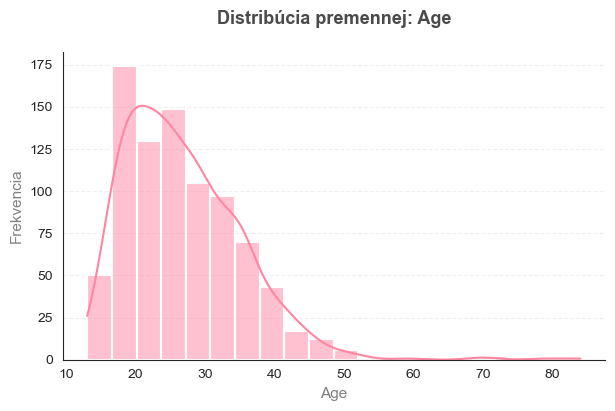

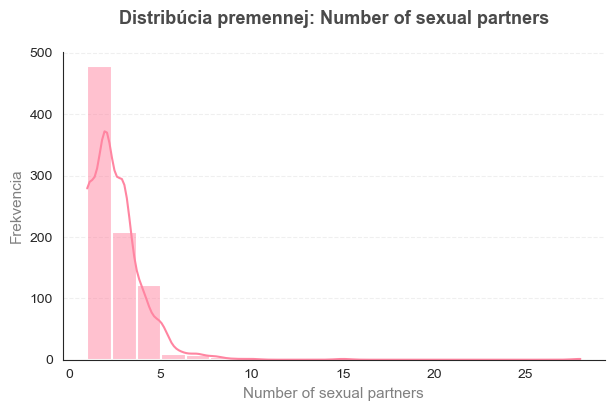

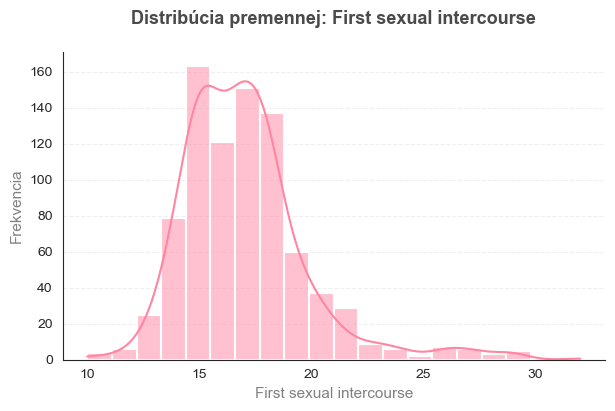

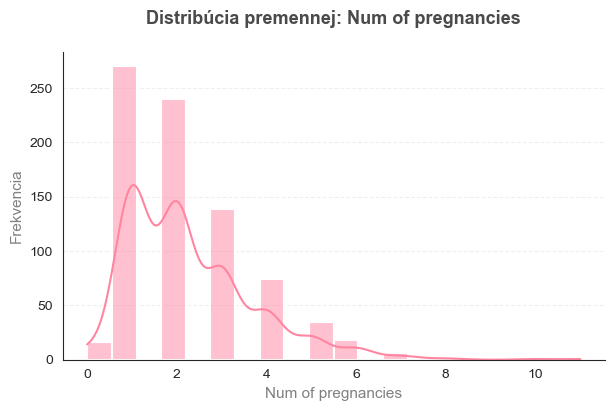

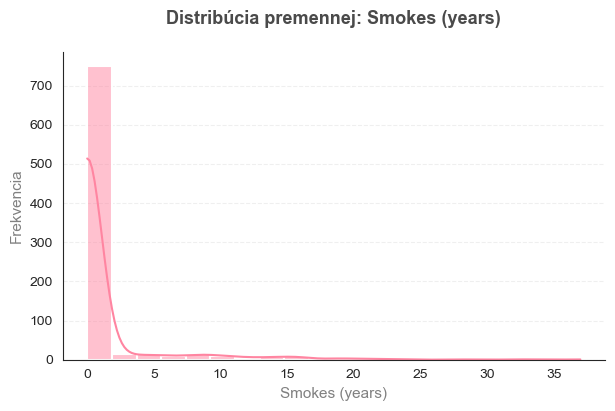

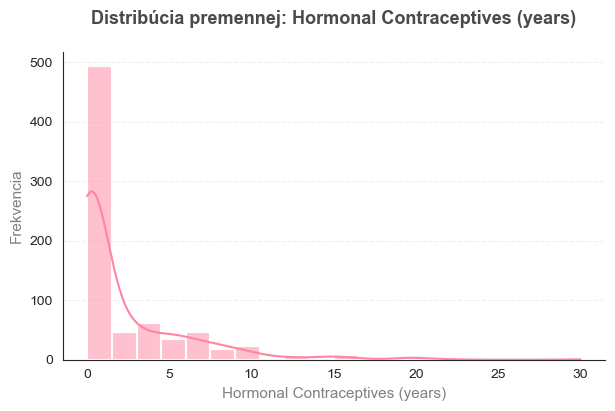

In [60]:
#Plot histograms with KDE for each selected numerical column to visualize distributions
sns.set_style("white") 

for col in selected_cols:
    plt.figure(figsize=(7, 4))
    
    sns.histplot(
        df[col].dropna(), 
        bins=20, 
        kde=True,          
        color="#FF85A1",   
        edgecolor="white", 
        linewidth=1.5
    )
    
    plt.title(f"Distribúcia premennej: {col}", fontsize=13, fontweight='bold', pad=20, color='#4A4A4A')
    plt.xlabel(col, fontsize=11, color='gray')
    plt.ylabel("Frekvencia", fontsize=11, color='gray')
    
    plt.grid(axis='y', linestyle='--', alpha=0.3)
    sns.despine()
    plt.savefig('missing_values_plot.png', dpi=300, bbox_inches='tight')
    plt.show()

In [61]:
for col in selected_cols:
    print(col, "max value:", df[col].max())  #Print the maximum value for each selected numerical column

Age max value: 84
Number of sexual partners max value: 28.0
First sexual intercourse max value: 32.0
Num of pregnancies max value: 11.0
Smokes (years) max value: 37.0
Hormonal Contraceptives (years) max value: 30.0


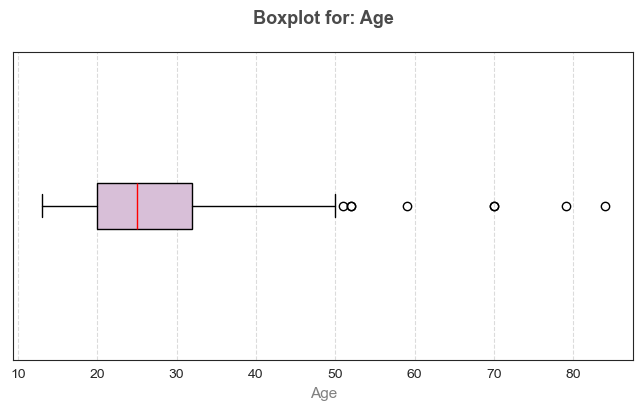

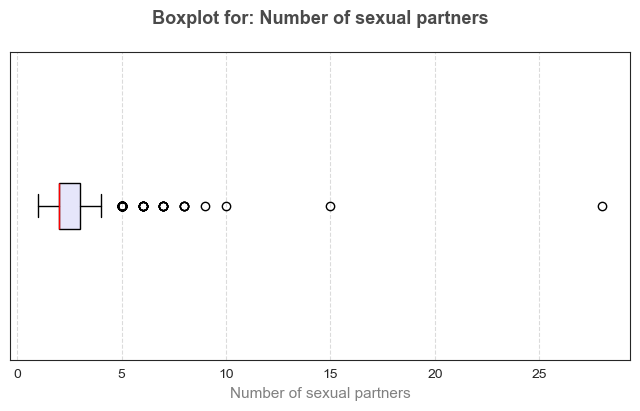

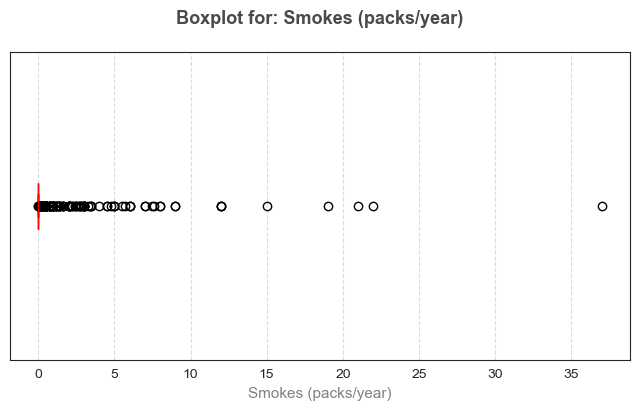

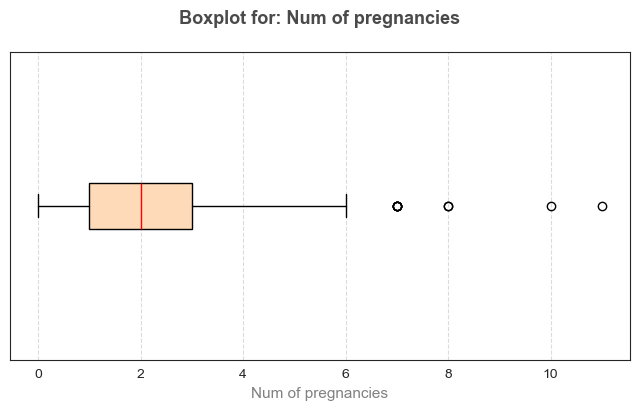

In [62]:
#Plot horizontal boxplots for selected columns to visualize outliers
outlier_cols = [ 
    'Age', 
    'Number of sexual partners', 
    'Smokes (packs/year)', 
    'Num of pregnancies'
]
colors = ['#D8BFD8', '#E6E6FA', '#F0E68C', '#FFDAB9']  

for i, col in enumerate(outlier_cols):
    plt.figure(figsize=(8, 4))
    
    box = plt.boxplot(
        df[col].dropna(),
        vert=False,
        patch_artist=True,
        medianprops={'color': 'red'}
    )
    
    for patch in box['boxes']:
        patch.set_facecolor(colors[i % len(colors)])
    
    plt.title(f"Boxplot for: {col}", fontsize=13, fontweight='bold', pad=20, color='#4A4A4A')
    plt.xlabel(col, fontsize=11, color='gray')
    plt.yticks([])
    plt.grid(axis='x', linestyle='--', alpha=0.7)
    plt.savefig('missing_values_plot.png', dpi=300, bbox_inches='tight')
    plt.show()

In [63]:
for col in outlier_cols: #Calculate IQR for each selected column and count the number of outliers outside 1.5*IQR
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    
    print(f"\nPremenná: {col}")
    print(f"IQR: {IQR}")
    print(f"Počet extrémnych hodnôt: {len(outliers)}")


Premenná: Age
IQR: 12.0
Počet extrémnych hodnôt: 8

Premenná: Number of sexual partners
IQR: 1.0
Počet extrémnych hodnôt: 68

Premenná: Smokes (packs/year)
IQR: 0.0
Počet extrémnych hodnôt: 123

Premenná: Num of pregnancies
IQR: 2.0
Počet extrémnych hodnôt: 10


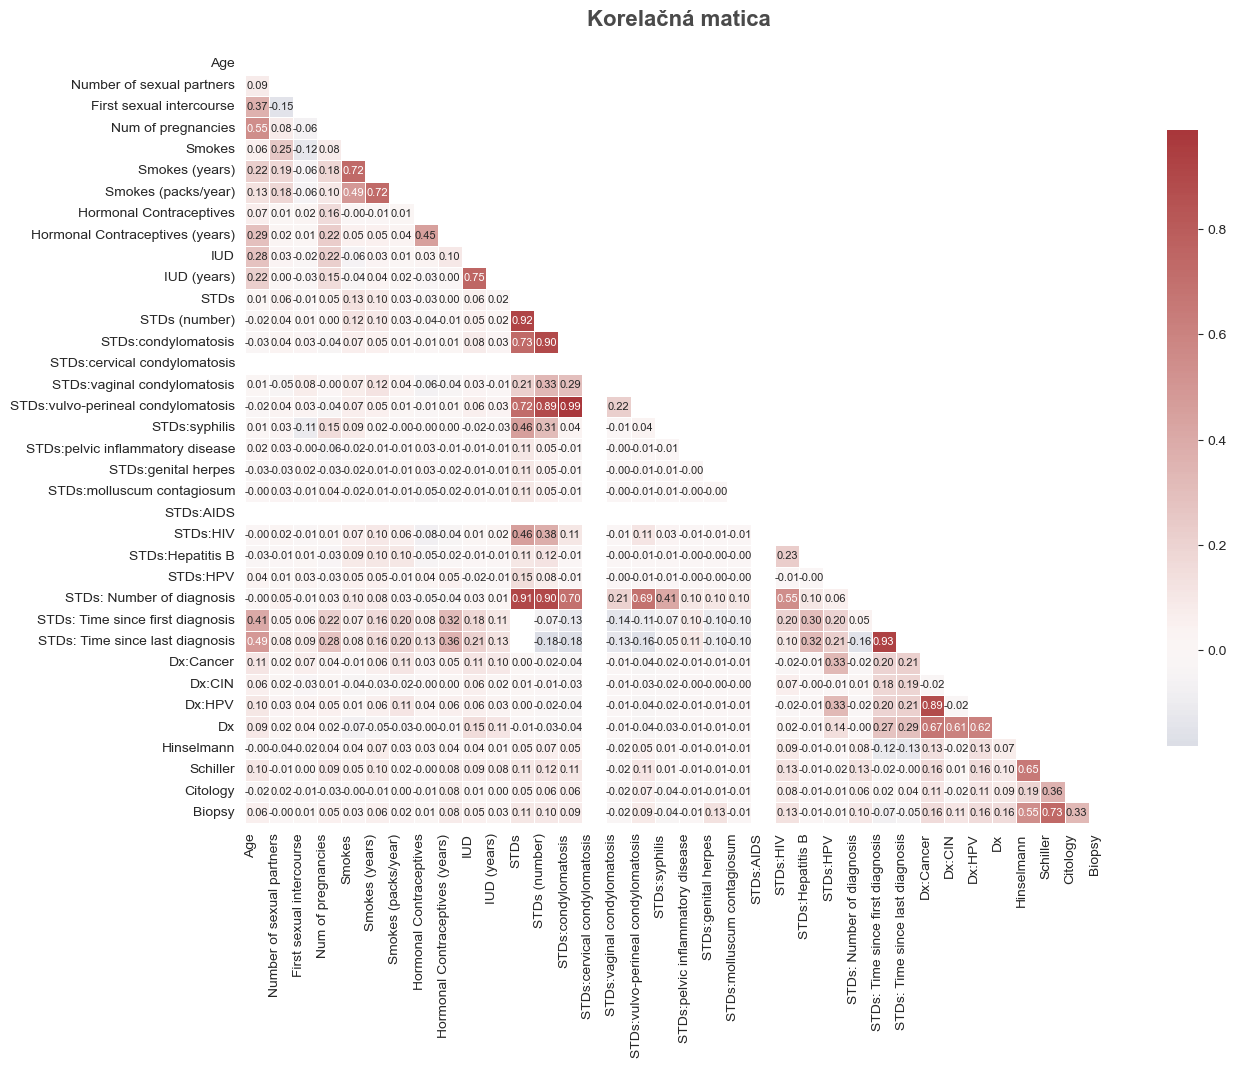

In [65]:
#Compute the correlation matrix for numerical columns and plot a triangular heatmap with annotations to visualize relationships
numeric_df = df.select_dtypes(include=['int64', 'float64']) 
corr_matrix = numeric_df.corr()

mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
plt.figure(figsize=(14, 10))
sns.heatmap(
    corr_matrix, 
    mask=mask, 
    annot=True,           
    fmt=".2f",            
    cmap='vlag',          
    center=0,             
    linewidths=.5,        
    cbar_kws={"shrink": .8}, 
    annot_kws={"size": 8} 
)

plt.title("Korelačná matica", fontsize=16, fontweight='bold', pad=20, color='#4A4A4A')
plt.xticks(rotation=90, ha='right') 
plt.savefig('missing_values_plot.png', dpi=300, bbox_inches='tight')
plt.show()

In [86]:
biopsy_corr = corr_matrix['Biopsy'].sort_values(ascending=False) #Isolate correlation values for the target variable 'Biopsy' and sort them

biopsy_corr_df = biopsy_corr.reset_index()
biopsy_corr_df.columns = ['Feature', 'Correlation with Biopsy']

biopsy_corr_df #Display the ranked features by their relationship with Biopsy

,Feature,Correlation with Biopsy
0,Biopsy,1.000000
1,Schiller,0.733204
2,Hinselmann,0.547417
3,Citology,0.327466
4,Dx:Cancer,0.160905
5,Dx:HPV,0.160905
6,Dx,0.157607
7,STDs:genital herpes,0.132526
8,STDs:HIV,0.126880
9,Dx:CIN,0.113172


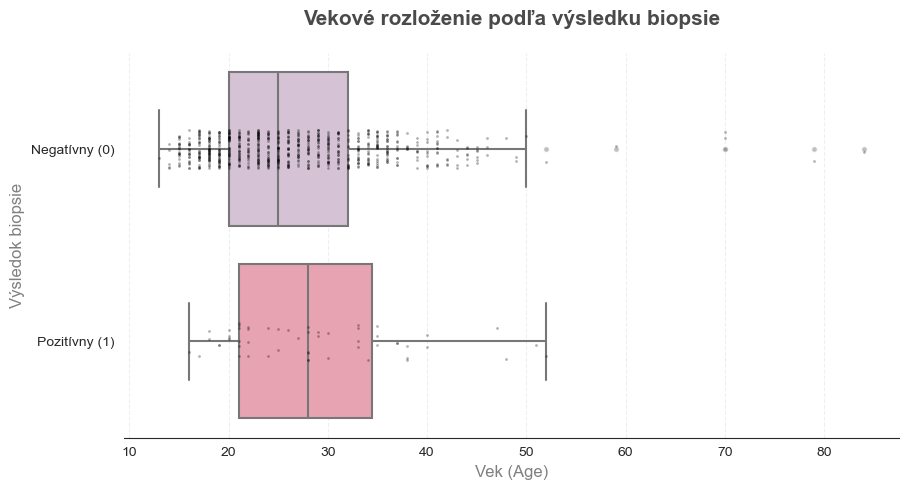

In [66]:
#Visualize age distribution for negative (0) and positive (1) biopsy results using a horizontal boxplot
sns.set_style("white")
plt.figure(figsize=(10, 5))
pastel_colors = {0: "#D8BFD8", 1: "#F497AD"}

sns.boxplot(
    x='Age', 
    y='Biopsy', 
    data=df, 
    orient='h', 
    palette=pastel_colors, 
    hue='Biopsy',      
    legend=False,
    linewidth=1.5,
    fliersize=4,       
    flierprops={"markerfacecolor": "gray", "markeredgecolor": "white", "alpha": 0.5}
)

sns.stripplot(
    x='Age', 
    y='Biopsy', 
    data=df, 
    orient='h', 
    color="black", 
    size=2, 
    alpha=0.3, 
    jitter=True
)

plt.title("Vekové rozloženie podľa výsledku biopsie", fontsize=15, fontweight='bold', pad=20, color='#4A4A4A')
plt.xlabel("Vek (Age)", fontsize=12, color='gray')
plt.ylabel("Výsledok biopsie", fontsize=12, color='gray')

plt.yticks([0, 1], ['Negatívny (0)', 'Pozitívny (1)'])

sns.despine(left=True)
plt.grid(axis='x', linestyle='--', alpha=0.3)
plt.savefig('missing_values_plot.png', dpi=300, bbox_inches='tight')
plt.show()

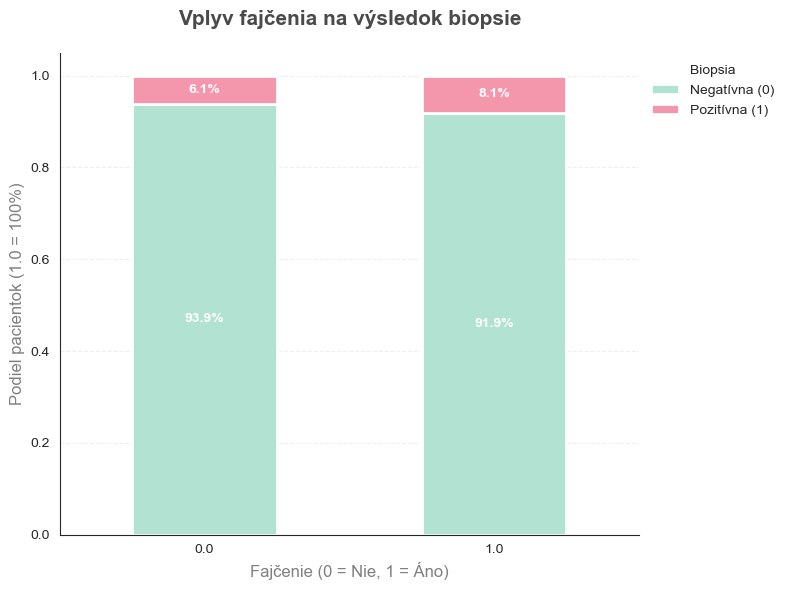

In [69]:
#Plot a stacked bar chart showing the proportion of negative (0) and positive (1) biopsy results for smokers vs non-smokers
smoke_biopsy = pd.crosstab(df['Smokes'], df['Biopsy'], normalize='index')

colors = ["#B2E2D2", "#F497AD"] 
ax = smoke_biopsy.plot(
    kind='bar', 
    stacked=True,          
    figsize=(8, 6), 
    color=colors, 
    edgecolor='white', 
    linewidth=2
)

plt.title("Vplyv fajčenia na výsledok biopsie", fontsize=15, fontweight='bold', pad=20, color='#4A4A4A')
plt.xlabel("Fajčenie (0 = Nie, 1 = Áno)", fontsize=12, color='gray')
plt.ylabel("Podiel pacientok (1.0 = 100%)", fontsize=12, color='gray')

plt.legend(
    title="Biopsia", 
    labels=['Negatívna (0)', 'Pozitívna (1)'], 
    loc='upper left', 
    bbox_to_anchor=(1, 1), 
    frameon=False
)

sns.despine()
plt.xticks(rotation=0) 
plt.grid(axis='y', linestyle='--', alpha=0.3)

for p in ax.patches:
    width, height = p.get_width(), p.get_height()
    x, y = p.get_xy() 
    if height > 0.05: 
        ax.text(x + width/2, 
                y + height/2, 
                f'{height:.1%}', 
                ha='center', 
                va='center', 
                color='white', 
                fontweight='bold')

plt.tight_layout()
plt.savefig('missing_values_plot.png', dpi=300, bbox_inches='tight')
plt.show()

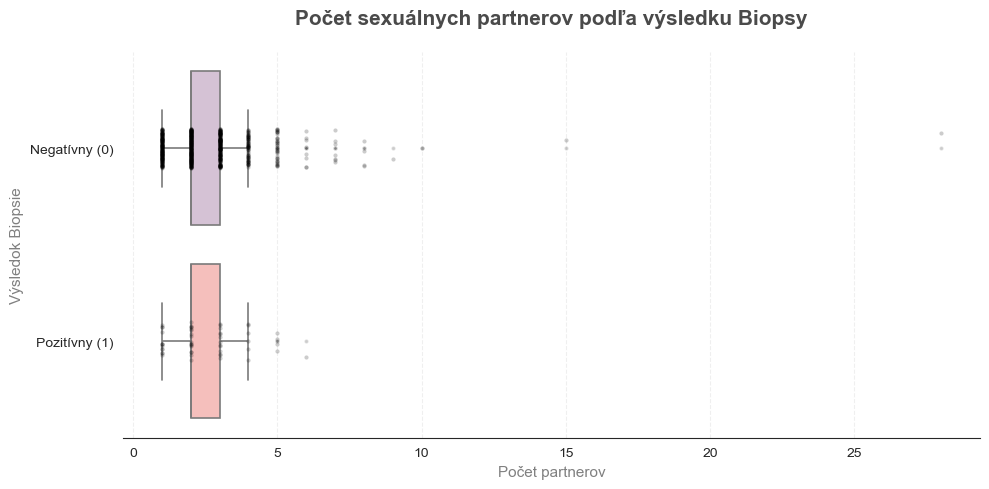

In [68]:
sns.set_style("white")
plt.figure(figsize=(10, 5))

my_palette = {0: "#D8BFD8", 1: "#FFB7B2"}

sns.boxplot(
    x='Number of sexual partners', 
    y='Biopsy', 
    data=df, 
    orient='h', 
    palette=my_palette, 
    hue='Biopsy', 
    legend=False,
    linewidth=1.2,
    fliersize=3,        
    flierprops={"markerfacecolor": "gray", "markeredgecolor": "white", "alpha": 0.4}
)

sns.stripplot(
    x='Number of sexual partners', 
    y='Biopsy', 
    data=df, 
    orient='h', 
    size=3, 
    color="black", 
    alpha=0.2, 
    jitter=True
)

plt.title("Počet sexuálnych partnerov podľa výsledku Biopsy", fontsize=15, fontweight='bold', pad=20, color='#4A4A4A')
plt.xlabel("Počet partnerov", fontsize=11, color='gray')
plt.ylabel("Výsledok Biopsie", fontsize=11, color='gray')

plt.yticks([0, 1], ['Negatívny (0)', 'Pozitívny (1)'])
#plt.xlim(-0.5, 15) 

sns.despine(left=True)
plt.grid(axis='x', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.savefig('missing_values_plot.png', dpi=300, bbox_inches='tight')
plt.show()

In [90]:
df.groupby('Biopsy')[['Age', 'Number of sexual partners']].mean() #Calculate the mean Age and Number of sexual partners for each Biopsy outcome (0 = negative, 1 = positive) 

,Age,Number of sexual partners
Biopsy,,
0,26.696139,2.528278
1,28.636364,2.518519


In [91]:
df.groupby('Biopsy')[['Age', 'Number of sexual partners']].median() #Calculate the median Age and Number of sexual partners for each Biopsy outcome (0 = negative, 1 = positive) 

,Age,Number of sexual partners
Biopsy,,
0,25.0,2.0
1,28.0,2.0


In [92]:
df[(df['Smokes'] == 0) & (df['Smokes (years)'] > 0)] #Filter rows where patients are marked as non-smokers (Smokes = 0) but have a nonzero smoking duration (Smokes (years) > 0)

,Age,Number of sexual partners,First sexual intercourse,Num of pregnancies,Smokes,Smokes (years),Smokes (packs/year),Hormonal Contraceptives,Hormonal Contraceptives (years),IUD,...,STDs: Time since first diagnosis,STDs: Time since last diagnosis,Dx:Cancer,Dx:CIN,Dx:HPV,Dx,Hinselmann,Schiller,Citology,Biopsy


In [93]:
df[(df['Smokes'] == 0) & (df['Smokes (packs/year)'] > 0)] #Filter rows where patients are marked as non-smokers (Smokes = 0) but report a nonzero smoking rate (Smokes (packs/year) > 0)

,Age,Number of sexual partners,First sexual intercourse,Num of pregnancies,Smokes,Smokes (years),Smokes (packs/year),Hormonal Contraceptives,Hormonal Contraceptives (years),IUD,...,STDs: Time since first diagnosis,STDs: Time since last diagnosis,Dx:Cancer,Dx:CIN,Dx:HPV,Dx,Hinselmann,Schiller,Citology,Biopsy


In [94]:
df[(df['STDs'] == 0) & (df['STDs (number)'] > 0)] # Filter rows where patients are marked as having no STDs (STDs = 0) but report a nonzero number of STDs (STDs (number) > 0)

,Age,Number of sexual partners,First sexual intercourse,Num of pregnancies,Smokes,Smokes (years),Smokes (packs/year),Hormonal Contraceptives,Hormonal Contraceptives (years),IUD,...,STDs: Time since first diagnosis,STDs: Time since last diagnosis,Dx:Cancer,Dx:CIN,Dx:HPV,Dx,Hinselmann,Schiller,Citology,Biopsy


In [95]:
df[(df['IUD'] == 0) & (df['IUD (years)'] > 0)] # Filter rows where patients are marked as not using IUD (IUD = 0) but report a nonzero duration of use (IUD (years) > 0)

,Age,Number of sexual partners,First sexual intercourse,Num of pregnancies,Smokes,Smokes (years),Smokes (packs/year),Hormonal Contraceptives,Hormonal Contraceptives (years),IUD,...,STDs: Time since first diagnosis,STDs: Time since last diagnosis,Dx:Cancer,Dx:CIN,Dx:HPV,Dx,Hinselmann,Schiller,Citology,Biopsy


In [96]:
std_specific = [col for col in df.columns if 'STDs:' in col and 'Time' not in col] #Identify rows where patients are marked as having no STDs (STDs = 0) but report positive values in specific STD columns

df[(df['STDs'] == 0) & (df[std_specific].sum(axis=1) > 0)]

,Age,Number of sexual partners,First sexual intercourse,Num of pregnancies,Smokes,Smokes (years),Smokes (packs/year),Hormonal Contraceptives,Hormonal Contraceptives (years),IUD,...,STDs: Time since first diagnosis,STDs: Time since last diagnosis,Dx:Cancer,Dx:CIN,Dx:HPV,Dx,Hinselmann,Schiller,Citology,Biopsy


In [97]:
df["Num of pregnancies"].value_counts().sort_index() #Count the occurrences of each value in the 'Num of pregnancies' column and sort by number of pregnancies

Num of pregnancies
0.0      16
1.0     270
2.0     240
3.0     139
4.0      74
5.0      35
6.0      18
7.0       6
8.0       2
10.0      1
11.0      1
Name: count, dtype: int64

In [98]:
pd.crosstab(df["Num of pregnancies"], df["Biopsy"]) #Create a crosstab showing the frequency of each number of pregnancies by Biopsy outcome

Biopsy,0,1
Num of pregnancies,,
0.0,15,1
1.0,258,12
2.0,229,11
3.0,128,11
4.0,63,11
5.0,34,1
6.0,17,1
7.0,6,0
8.0,2,0


In [99]:
df.groupby("Biopsy")["Num of pregnancies"].mean() #Calculate the mean number of pregnancies for each Biopsy outcome (0 = negative, 1 = positive)

Biopsy
0    2.258621
1    2.541667
Name: Num of pregnancies, dtype: float64

In [100]:
df.groupby("Biopsy")["Num of pregnancies"].median() #Calculate the median number of pregnancies for each Biopsy outcome (0 = negative, 1 = positive)

Biopsy
0    2.0
1    2.5
Name: Num of pregnancies, dtype: float64

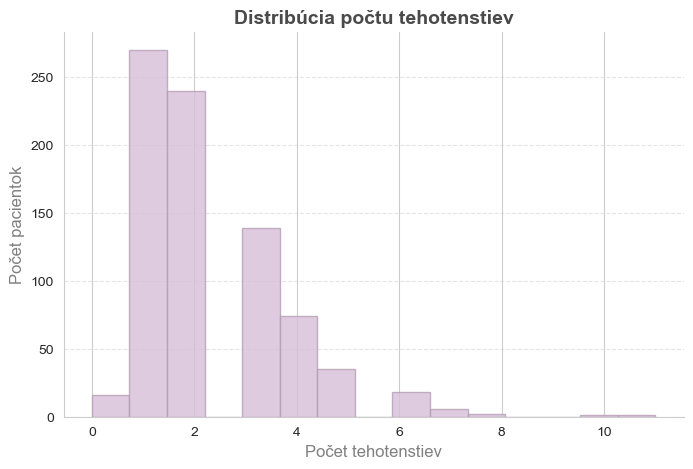

In [101]:
# Visualize the distribution of the number of pregnancies among patients
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid") 
plt.figure(figsize=(8, 5))
plt.hist(
    df["Num of pregnancies"].dropna(), 
    bins=15, 
    color="#D8BFD8", 
    edgecolor="#B39EB5", 
    alpha=0.8
)  

plt.xlabel("Počet tehotenstiev", fontsize=12, color='gray') # Number of Pregnancies
plt.ylabel("Počet pacientok", fontsize=12, color='gray')    # Count
plt.title("Distribúcia počtu tehotenstiev", fontsize=14, fontweight='bold', color='#4A4A4A') # Distribution of...

plt.grid(axis='y', linestyle='--', alpha=0.5) 
sns.despine() 

plt.show()

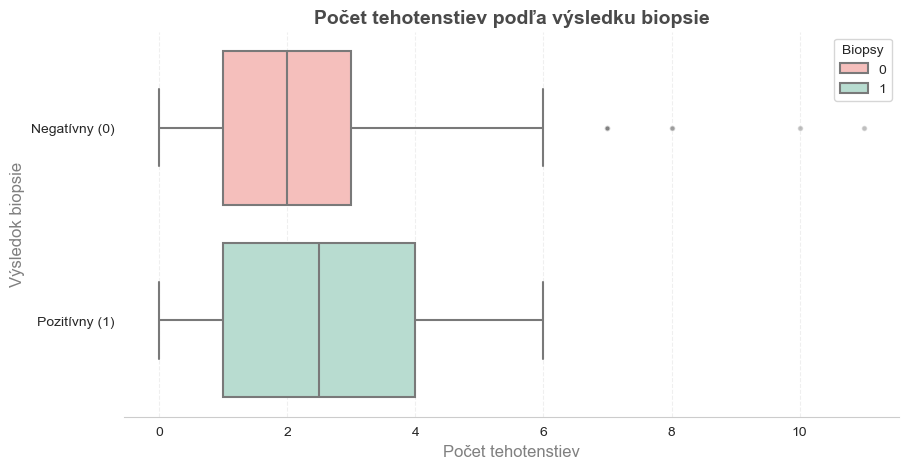

In [70]:
# Visualize the distribution of the number of pregnancies grouped by biopsy results using a horizontal boxplot
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")  
plt.figure(figsize=(10, 5))

pastel_colors = {0: "#FFB7B2", 1: "#B2E2D2"}  

sns.boxplot(
    data=df, 
    x="Num of pregnancies", 
    y="Biopsy", 
    orient="h", 
    palette=pastel_colors, 
    hue="Biopsy",  
    linewidth=1.5,
    fliersize=4,
    flierprops={"markerfacecolor": "gray", "markeredgecolor": "white", "alpha": 0.5}
)

plt.title("Počet tehotenstiev podľa výsledku biopsie", fontsize=14, fontweight='bold', color='#4A4A4A')
plt.xlabel("Počet tehotenstiev", fontsize=12, color='gray')
plt.ylabel("Výsledok biopsie", fontsize=12, color='gray')

plt.yticks([0, 1], ['Negatívny (0)', 'Pozitívny (1)'])

sns.despine(left=True)  
plt.grid(axis='x', linestyle='--', alpha=0.3)
plt.savefig('missing_values_plot.png', dpi=300, bbox_inches='tight')
plt.show()

In [103]:
# Calculate the correlation coefficient between the number of pregnancies and the biopsy result
df[["Num of pregnancies", "Biopsy"]].corr()

,Num of pregnancies,Biopsy
Num of pregnancies,1.000000,0.046416
Biopsy,0.046416,1.000000
